In [ ]:
from google.colab import files

uploaded = files.upload()

Saving ipl_match_metrics_new_rerun.csv to ipl_match_metrics_new_rerun.csv


Enter IPL season (2008-2026): 2009

IPL 2009 Team Statistics
                       Team  Matches  Wins       NRR      NRRR  win_rate
             Mumbai Indians       13     5  0.680830  0.126647  0.384615
Royal Challengers Bengaluru       16     9 -0.115202 -0.030931  0.562500
               Punjab Kings       14     7 -0.572623 -0.072786  0.500000
      Kolkata Knight Riders       13     3 -1.333155 -0.368176  0.230769
        Chennai Super Kings       14     8  0.942899  0.188766  0.571429
            Deccan Chargers       16     9  0.742082  0.241935  0.562500
             Delhi Capitals       15    10  0.532777  0.099015  0.666667
           Rajasthan Royals       13     5 -0.977656 -0.183328  0.384615


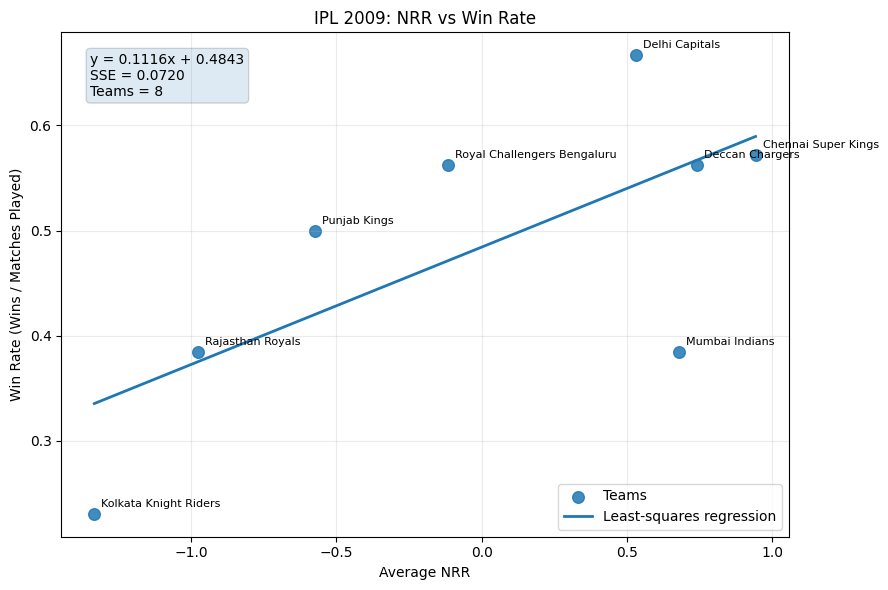

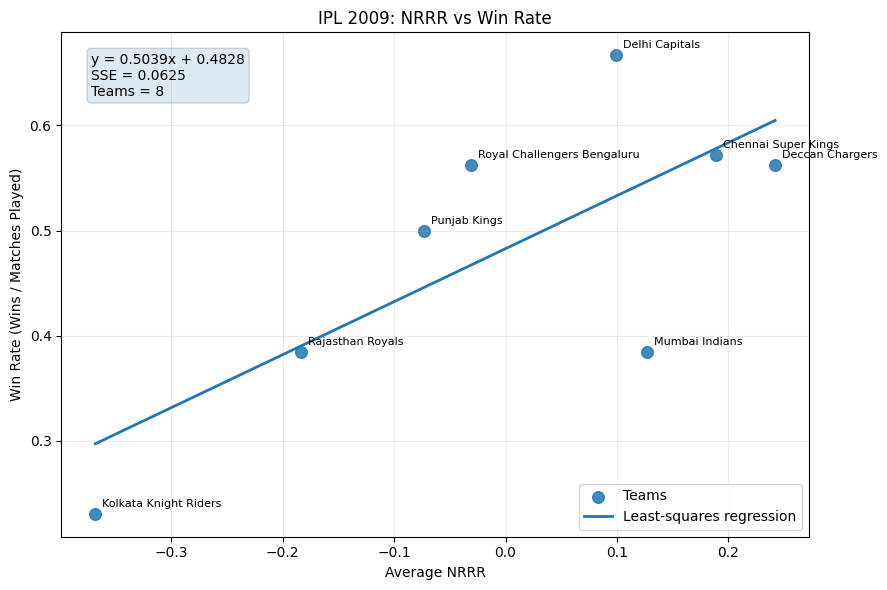


IPL 2009 Regression Results
 Year Model    Slope  Intercept      SSE
 2009   NRR 0.111554   0.484282 0.072003
 2009  NRRR 0.503875   0.482815 0.062456


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# LOAD DATA


INPUT_FILE = "/content/ipl_match_metrics_new_rerun.csv"

df = pd.read_csv(INPUT_FILE)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["Year"] = df["date"].dt.year


#  SELECT IPL SEASON


YEAR = int(input("Enter IPL season (2008-2026): "))

if YEAR < 2008 or YEAR > 2026:
    raise ValueError("Please enter a year between 2008 and 2026.")

season_df = df[df["Year"] == YEAR].copy()

if season_df.empty:
    raise ValueError(f"No data found for IPL {YEAR}.")


#  TEAM-LEVEL AGGREGATION


teams = pd.concat([
    season_df["Team1"],
    season_df["Team2"]
]).dropna().unique()

team_stats = []

for team in teams:

    t1_df = season_df[season_df["Team1"] == team]
    t2_df = season_df[season_df["Team2"] == team]

    total_matches = len(t1_df) + len(t2_df)

    if total_matches == 0:
        continue

    wins = (season_df["Winner"] == team).sum()

    avg_nrr = (
        t1_df["netnrr1"].sum()
        + t2_df["netnrr2"].sum()
    ) / total_matches

    avg_nrrr = (
        t1_df["netnrrr1"].sum()
        + t2_df["netnrrr2"].sum()
    ) / total_matches

    win_rate = wins / total_matches

    team_stats.append({
        "Team": team,
        "Matches": total_matches,
        "Wins": wins,
        "NRR": avg_nrr,
        "NRRR": avg_nrrr,
        "win_rate": win_rate
    })

team_df = pd.DataFrame(team_stats)

print(f"\nIPL {YEAR} Team Statistics")
print("=" * 40)
print(team_df.to_string(index=False))

# 4. LEAST-SQUARES REGRESSION

def linear_regression(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    x_mean = np.mean(x)
    y_mean = np.mean(y)

    denominator = np.sum((x - x_mean) ** 2)

    if len(x) < 2 or denominator == 0:
        raise ValueError("Regression cannot be fitted.")

    slope = np.sum(
        (x - x_mean) * (y - y_mean)
    ) / denominator

    intercept = y_mean - slope * x_mean

    y_pred = slope * x + intercept

    residuals = y - y_pred

    sse = np.sum(residuals ** 2)

    return slope, intercept, sse, y_pred


# PLOT REGRESSION


def plot_regression(metric, title):

    x = team_df[metric].to_numpy()
    y = team_df["win_rate"].to_numpy()

    slope, intercept, sse, y_pred = linear_regression(x, y)

    # Sort x-values for a smooth regression line
    order = np.argsort(x)

    plt.figure(figsize=(9, 6))

    # Scatter plot
    plt.scatter(
        x, y,
        s=70,
        alpha=0.85,
        label="Teams"
    )

    # Regression line
    plt.plot(
        x[order],
        y_pred[order],
        linewidth=2,
        label="Least-squares regression"
    )

    # Team labels
    for i, team in enumerate(team_df["Team"]):
        plt.annotate(
            team,
            (x[i], y[i]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

    # Regression equation
    equation = (
        f"y = {slope:.4f}x + {intercept:.4f}\n"
        f"SSE = {sse:.4f}\n"
        f"Teams = {len(team_df)}"
    )

    plt.text(
        0.04, 0.96,
        equation,
        transform=plt.gca().transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", alpha=0.15),
        fontsize=10
    )

    plt.title(f"IPL {YEAR}: {title}")
    plt.xlabel(f"Average {metric}")
    plt.ylabel("Win Rate (Wins / Matches Played)")

    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return {
        "Year": YEAR,
        "Model": metric,
        "Slope": slope,
        "Intercept": intercept,
        "SSE": sse
    }

# ==========================================
# 6. GENERATE BOTH REGRESSION PLOTS
# ==========================================

result_nrr = plot_regression(
    "NRR",
    "NRR vs Win Rate"
)

result_nrrr = plot_regression(
    "NRRR",
    "NRRR vs Win Rate"
)


# DISPLAY MODEL COMPARISON

results = pd.DataFrame([
    result_nrr,
    result_nrrr
])

print(f"\nIPL {YEAR} Regression Results")
print("=" * 40)
print(results.to_string(index=False))


In [ ]:
# Collect regression parameters for all available seasons
all_seasons_stats = []

unique_years = sorted(df["Year"].dropna().unique())

for yr in unique_years:
    season_df_temp = df[df["Year"] == yr].copy()
    teams_temp = pd.concat([
        season_df_temp["Team1"],
        season_df_temp["Team2"]
    ]).dropna().unique()

    team_stats_temp = []
    for team in teams_temp:
        t1_df = season_df_temp[season_df_temp["Team1"] == team]
        t2_df = season_df_temp[season_df_temp["Team2"] == team]
        total_matches = len(t1_df) + len(t2_df)
        if total_matches == 0:
            continue
        wins = (season_df_temp["Winner"] == team).sum()
        avg_nrr = (t1_df["netnrr1"].sum() + t2_df["netnrr2"].sum()) / total_matches
        avg_nrrr = (t1_df["netnrrr1"].sum() + t2_df["netnrrr2"].sum()) / total_matches
        win_rate = wins / total_matches

        team_stats_temp.append({
            "Team": team,
            "NRR": avg_nrr,
            "NRRR": avg_nrrr,
            "win_rate": win_rate
        })

    temp_team_df = pd.DataFrame(team_stats_temp)
    if len(temp_team_df) < 2:
        continue

    # Calculate linear regression for NRR
    try:
        slope_nrr, intercept_nrr, _, _ = linear_regression(temp_team_df["NRR"], temp_team_df["win_rate"])
    except ValueError:
        slope_nrr, intercept_nrr = np.nan, np.nan

    # Calculate linear regression for NRRR
    try:
        slope_nrrr, intercept_nrrr, _, _ = linear_regression(temp_team_df["NRRR"], temp_team_df["win_rate"])
    except ValueError:
        slope_nrrr, intercept_nrrr = np.nan, np.nan

    all_seasons_stats.append({
        "Season": int(yr),
        "NRR_Slope": slope_nrr,
        "NRR_Intercept": intercept_nrr,
        "NRRR_Slope": slope_nrrr,
        "NRRR_Intercept": intercept_nrrr
    })

# Create DataFrame and save to CSV
regression_summary_df = pd.DataFrame(all_seasons_stats)
output_csv_path = "/content/ipl_seasons_regression_summary.csv"
regression_summary_df.to_csv(output_csv_path, index=False)

print(f"Regression metrics saved successfully to {output_csv_path}")
display(regression_summary_df)

Regression metrics saved successfully to /content/ipl_seasons_regression_summary.csv


,Season,NRR_Slope,NRR_Intercept,NRRR_Slope,NRRR_Intercept
0,2008,0.097755,0.488652,0.306116,0.489364
1,2009,0.111554,0.484282,0.503875,0.482815
2,2010,0.163995,0.485712,0.464691,0.486663
3,2011,0.127191,0.488012,0.356301,0.487148
4,2012,0.136743,0.496006,0.595309,0.496142
5,2013,0.240596,0.472252,0.852553,0.472120
6,2014,0.216317,0.480015,0.869834,0.479204
7,2015,0.167340,0.469703,0.655481,0.467693
8,2016,0.098992,0.493537,0.273735,0.493768
9,2017,0.137649,0.475551,0.379272,0.478685
